# Exercice 3 - Espérance du risque empirique de l'OLS

## Cadre et notations :

On se place dans le modèle linéaire à design fixe rappelé par l'énoncé.

- Le design $X \in \mathbb{R}^{n \times d}$ est déterministe et fixé, supposé injectif. Son rang vaut donc $d$, ce qui impose $d \leqslant n$ et rend $X^\top X$ inversible.
- Les étiquettes suivent $y = X\theta^* + \varepsilon$, où $\varepsilon \in \mathbb{R}^n$ est un bruit gaussien centré de matrice de covariance $\sigma^2 I_n$, avec $\sigma^2 > 0$. Les composantes $\varepsilon_i$ sont indépendantes, centrées et de variance $\sigma^2$.
- Le risque empirique s'écrit $R_n(\theta) = \frac{1}{n}\lVert y - X\theta \rVert^2$, avec $\lVert\cdot\rVert = \lVert\cdot\rVert_2$.
- L'estimateur des moindres carrés $\hat\theta = (X^\top X)^{-1} X^\top y$ minimise le risque empirique.

On note $P_X = X (X^\top X)^{-1} X^\top$ la matrice de projection orthogonale sur $\operatorname{Im}(X)$, et $A = I_n - P_X$.

Objectif (Proposition 1) : $\displaystyle \mathbb{E}\big[R_n(\hat\theta)\big] = \frac{n-d}{n}\,\sigma^2.$

Remarque : les preuves n'utilisent que la structure au second ordre du bruit, c'est-à-dire $\mathbb{E}[\varepsilon] = 0$ et $\operatorname{Cov}(\varepsilon) = \sigma^2 I_n$ (composantes centrées, non corrélées, de variance $\sigma^2$). L'indépendance et la gaussianité du modèle impliquent ces propriétés mais ne servent pas au-delà.

## Question 1 (M) : comparaison au risque de Bayes

Pour chaque point $x_i$ du design, la prédiction qui minimise l'erreur quadratique attendue sur $y_i = x_i^\top\theta^* + \varepsilon_i$ est $\mathbb{E}[y_i] = x_i^\top\theta^*$. Le meilleur risque atteignable, c'est-à-dire le risque de Bayes, vaut donc

$$R^* = \mathbb{E}\Big[\tfrac{1}{n}\textstyle\sum_i (y_i - x_i^\top\theta^*)^2\Big] = \tfrac{1}{n}\textstyle\sum_i \operatorname{Var}(\varepsilon_i) = \sigma^2 .$$

Comme $0 < d \leqslant n$ et $\sigma^2 > 0$ :

$$\mathbb{E}\big[R_n(\hat\theta)\big] = \Big(1 - \frac{d}{n}\Big)\sigma^2 \;<\; \sigma^2 = R^* .$$

La valeur de la Proposition 1 est donc plus petite que le risque de Bayes.

Interprétation : le risque empirique de l'OLS est optimiste. L'estimateur $\hat\theta$ est ajusté sur les mêmes données que celles qui servent à mesurer l'erreur. Il absorbe une partie du bruit de l'échantillon, et l'erreur mesurée passe sous le plancher $\sigma^2$ qu'aucun prédicteur ne peut battre en généralisation.

Discussion en fonction de $n$ et $d$ :

- L'écart au risque de Bayes vaut $\frac{d}{n}\sigma^2$ et croît avec $d$ : plus le modèle a de paramètres, plus il ajuste de bruit. Le cas extrême $d = n$ donne une matrice $X$ carrée inversible. L'OLS interpole alors exactement les données ($R_n(\hat\theta) = 0$) tandis que le vrai risque reste supérieur ou égal à $\sigma^2$. C'est le surapprentissage maximal.
- À $d$ fixé, $\frac{n-d}{n}\sigma^2 \to \sigma^2$ quand $n \to \infty$. L'optimisme disparaît quand les données abondent.

Le tableau est symétrique du côté de la généralisation. Considérons une copie fraîche du dataset avec le même design, $y' = X\theta^* + \varepsilon'$, où $\varepsilon'$ a la même loi que $\varepsilon$ et en est indépendant. L'erreur de test attendue de $\hat\theta$ vaut alors

$$\mathbb{E}\Big[\tfrac{1}{n}\lVert y' - X\hat\theta\rVert^2\Big] = \tfrac{1}{n}\,\mathbb{E}\big[\lVert \varepsilon'\rVert^2\big] + \tfrac{1}{n}\,\mathbb{E}\big[\lVert X(\hat\theta - \theta^*)\rVert^2\big] = \sigma^2 + \tfrac{d}{n}\,\sigma^2,$$

le terme croisé étant nul par indépendance de $\varepsilon'$ et $\hat\theta$. En effet $X(\hat\theta - \theta^*) = P_X\,\varepsilon$, et les identités des Questions 4 et 5 appliquées à $P_X$ (elle aussi symétrique idempotente) donnent $\mathbb{E}\lVert P_X\varepsilon\rVert^2 = \sigma^2\operatorname{tr}(P_X) = \sigma^2 d$. L'erreur d'apprentissage est donc sous $R^*$ de $\frac{d}{n}\sigma^2$ et l'erreur de test au-dessus du même montant. C'est exactement cet optimisme que corrige le facteur $n - d$ de la Question 7.

## Question 2 (M) : réécriture du résidu

Le vecteur des prédictions de l'OLS s'écrit

$$X\hat\theta = X(X^\top X)^{-1}X^\top y = P_X\, y,$$

donc le résidu vaut $y - X\hat\theta = (I_n - P_X)\,y = A\,y$. Injectons le modèle $y = X\theta^* + \varepsilon$ :

$$A\,y = A X \theta^* + A\,\varepsilon .$$

Or

$$AX = (I_n - P_X)X = X - X(X^\top X)^{-1}(X^\top X) = X - X = 0,$$

le terme de signal disparaît et il reste $y - X\hat\theta = A\,\varepsilon$. D'où $R_n(\hat\theta) = \frac{1}{n}\lVert A\varepsilon\rVert^2$. En prenant l'espérance (le seul aléa est $\varepsilon$, le design étant fixe) :

$$\boxed{\;\mathbb{E}\big[R_n(\hat\theta)\big] = \mathbb{E}_\varepsilon\Big[\tfrac{1}{n}\big\lVert \big(I_n - X(X^\top X)^{-1}X^\top\big)\varepsilon \big\rVert^2\Big].\;}$$

## Question 3 (M) : somme des carrés et trace

Soit $A \in \mathbb{R}^{n \times n}$ quelconque. Par définition de la transposée, $(A^\top)_{ji} = A_{ij}$. Le coefficient diagonal $j$ de $A^\top A$ vaut donc

$$(A^\top A)_{jj} = \sum_{i=1}^{n} (A^\top)_{ji}\,A_{ij} = \sum_{i=1}^{n} A_{ij}^2 .$$

En sommant sur $j$ :

$$\operatorname{tr}(A^\top A) = \sum_{j=1}^{n} (A^\top A)_{jj} = \sum_{j=1}^{n}\sum_{i=1}^{n} A_{ij}^2 = \sum_{(i,j) \in [1,n]^2} A_{ij}^2 .$$

## Question 4 (M) : espérance de $\frac{1}{n}\lVert A\varepsilon\rVert^2$

On développe la forme quadratique :

$$\lVert A\varepsilon\rVert^2 = \varepsilon^\top A^\top A\, \varepsilon = \sum_{i,j} (A^\top A)_{ij}\, \varepsilon_i \varepsilon_j .$$

Le bruit est centré et de covariance $\sigma^2 I_n$ (composantes non corrélées, ce que l'indépendance du modèle implique). On en déduit $\mathbb{E}[\varepsilon_i \varepsilon_j] = \sigma^2 \delta_{ij}$ en distinguant deux cas : pour $i \neq j$, $\mathbb{E}[\varepsilon_i \varepsilon_j] = \mathbb{E}[\varepsilon_i]\,\mathbb{E}[\varepsilon_j] = 0$ par indépendance et centrage, et pour $i = j$, $\mathbb{E}[\varepsilon_i^2] = \operatorname{Var}(\varepsilon_i) = \sigma^2$. C'est ici, et seulement ici, que servent les hypothèses sur $\varepsilon$. Par linéarité de l'espérance :

$$\mathbb{E}\big[\lVert A\varepsilon\rVert^2\big] = \sum_{i,j} (A^\top A)_{ij}\, \sigma^2 \delta_{ij} = \sigma^2 \sum_{i} (A^\top A)_{ii} = \sigma^2 \operatorname{tr}(A^\top A).$$

En divisant par $n$ :

$$\boxed{\;\mathbb{E}_\varepsilon\Big[\tfrac{1}{n}\lVert A\varepsilon\rVert^2\Big] = \frac{\sigma^2}{n}\operatorname{tr}(A^\top A).\;}$$

## Question 5 (M) : montrer $A^\top A = A$

Montrons d'abord que $P_X = X(X^\top X)^{-1}X^\top$ est symétrique et idempotente.

Symétrie : posons $M = X^\top X$, qui est symétrique. En transposant $M M^{-1} = I_d$, on obtient $(M^{-1})^\top M^\top = I_d$, donc $(M^{-1})^\top = (M^\top)^{-1} = M^{-1}$ : l'inverse d'une matrice symétrique est symétrique. Ainsi

$$P_X^\top = \big(X(X^\top X)^{-1}X^\top\big)^\top = X \big((X^\top X)^{-1}\big)^\top X^\top = P_X .$$

Idempotence :

$$P_X^2 = X(X^\top X)^{-1}\underbrace{(X^\top X)(X^\top X)^{-1}}_{=\,I_d}X^\top = P_X .$$

Alors $A = I_n - P_X$ est symétrique, puisque $A^\top = I_n - P_X^\top = A$, et idempotente :

$$A^2 = (I_n - P_X)^2 = I_n - 2P_X + P_X^2 = I_n - P_X = A .$$

En combinant les deux propriétés : $A^\top A = A \cdot A = A^2 = A$. $ $

## Question 6 (M) : conclusion, preuve de la Proposition 1

Par la Question 5, $\operatorname{tr}(A^\top A) = \operatorname{tr}(A)$. Calculons cette trace, avec la linéarité puis la cyclicité de la trace ($\operatorname{tr}(MN) = \operatorname{tr}(NM)$) :

$$\operatorname{tr}(P_X) = \operatorname{tr}\big(X(X^\top X)^{-1}X^\top\big) = \operatorname{tr}\big((X^\top X)^{-1}X^\top X\big) = \operatorname{tr}(I_d) = d,$$

$$\operatorname{tr}(A) = \operatorname{tr}(I_n) - \operatorname{tr}(P_X) = n - d .$$

En enchaînant les Questions 2, 4 et 5 :

$$\mathbb{E}\big[R_n(\hat\theta)\big] \overset{\text{Q2}}{=} \mathbb{E}_\varepsilon\Big[\tfrac{1}{n}\lVert A\varepsilon\rVert^2\Big] \overset{\text{Q4}}{=} \frac{\sigma^2}{n}\operatorname{tr}(A^\top A) \overset{\text{Q5}}{=} \frac{\sigma^2}{n}\operatorname{tr}(A) = \frac{n-d}{n}\,\sigma^2 .$$

## Question 7 (M) : un estimateur sans biais de $\sigma^2$

Puisque $\lVert y - X\hat\theta\rVert^2 = n\,R_n(\hat\theta)$, la Proposition 1 donne

$$\mathbb{E}\big[\lVert y - X\hat\theta\rVert^2\big] = n \cdot \frac{n-d}{n}\sigma^2 = (n-d)\,\sigma^2,$$

d'où

$$\boxed{\;\mathbb{E}\left[\frac{\lVert y - X\hat\theta\rVert^2}{n-d}\right] = \sigma^2 .\;}$$

Dès que $d < n$, la statistique $\hat\sigma^2 = \frac{\lVert y - X\hat\theta\rVert^2}{n-d}$ est donc un estimateur sans biais de la variance du bruit. Le cas limite $d = n$ la rend indéfinie : l'OLS interpole exactement les données et le résidu est nul. Le diviseur $n - d$, qui correspond aux degrés de liberté résiduels, compense exactement l'optimisme du risque empirique quantifié à la Question 1. Diviser par $n$ au lieu de $n - d$ sous-estimerait systématiquement $\sigma^2$.

## Question 8 (C) : simulation

La cellule suivante vérifie numériquement les deux résultats, avec $\sigma^2 = 4$ connu.

1. Sur un design fixe ($n = 200$, $d = 50$) et 5 000 tirages du bruit, la moyenne de $\hat\sigma^2 = \lVert y - X\hat\theta\rVert^2/(n-d)$ doit approcher $\sigma^2 = 4$.
2. La moyenne du risque empirique $R_n(\hat\theta)$ doit approcher $\frac{n-d}{n}\sigma^2 = 3$, donc rester sous le risque de Bayes $\sigma^2$. On trace aussi cette moyenne en fonction du ratio $d/n$ pour visualiser la décroissance linéaire prédite.

Design fixe n = 200, d = 50, sigma^2 = 4.0
  moyenne de sigma_hat^2          = 4.0034  (cible sigma^2 = 4.0)
  moyenne de R_n(theta_hat)       = 3.0025
  valeur théorique (n-d)/n*sigma^2 = 3.0000
  risque de Bayes sigma^2          = 4.0


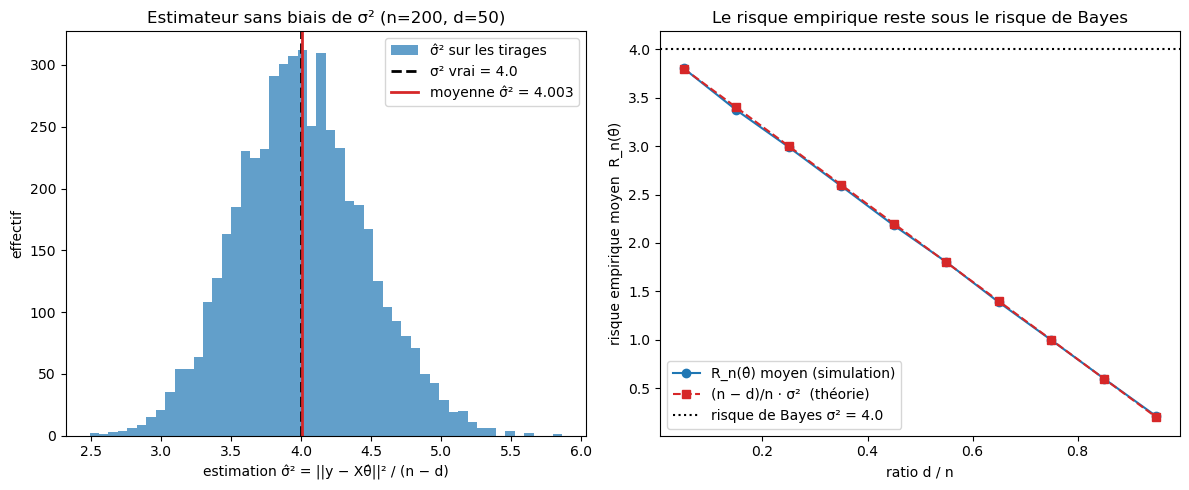

In [1]:
%matplotlib inline
# Question 8 : on fixe le design X une fois pour toutes, on retire le bruit un
# grand nombre de fois, et on vérifie que sigma_hat^2 = RSS/(n - d) est bien
# centré sur le vrai sigma^2 alors que le risque empirique moyen reste, lui,
# sous le risque de Bayes, exactement au niveau (n - d)/n * sigma^2 prédit.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(seed=0)
sigma2_vrai = 4.0


def ols_residual_sq(X, theta_star, sigma2):
    """
    Tire un bruit gaussien, ajuste l'OLS et renvoie la somme des carrés
    des résidus ||y - X theta_hat||².

    Paramètres :
        X (np.ndarray) : matrice de design (n, d), fixée.
        theta_star (np.ndarray) : vrai vecteur de coefficients (d,).
        sigma2 (float) : variance du bruit.

    Retour :
        float : somme des carrés des résidus de l'OLS.
    """
    n = X.shape[0]
    eps = rng.normal(0.0, np.sqrt(sigma2), size=n)
    y = X @ theta_star + eps
    theta_hat, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ theta_hat
    return float(resid @ resid)


# partie 1 : sigma_hat^2 comme estimateur sans biais, à design fixé
n, d = 200, 50
X = rng.standard_normal((n, d))
theta_star = rng.standard_normal(d)

n_trials = 5000
sigma2_hat = np.empty(n_trials)
rn = np.empty(n_trials)
for t in range(n_trials):
    rss = ols_residual_sq(X, theta_star, sigma2_vrai)
    sigma2_hat[t] = rss / (n - d)
    rn[t] = rss / n

print(f"Design fixe n = {n}, d = {d}, sigma^2 = {sigma2_vrai}")
print(f"  moyenne de sigma_hat^2          = {sigma2_hat.mean():.4f}  (cible sigma^2 = {sigma2_vrai})")
print(f"  moyenne de R_n(theta_hat)       = {rn.mean():.4f}")
print(f"  valeur théorique (n-d)/n*sigma^2 = {(n - d) / n * sigma2_vrai:.4f}")
print(f"  risque de Bayes sigma^2          = {sigma2_vrai}")

# partie 2 : risque empirique moyen en fonction du ratio d/n
n_fixed = 200
ds = np.arange(10, 191, 20)
rn_mean = []
for d_ in ds:
    Xd = rng.standard_normal((n_fixed, d_))
    theta_d = rng.standard_normal(d_)
    vals = [ols_residual_sq(Xd, theta_d, sigma2_vrai) / n_fixed for _ in range(400)]
    rn_mean.append(np.mean(vals))
rn_mean = np.array(rn_mean)
theory = (n_fixed - ds) / n_fixed * sigma2_vrai

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(sigma2_hat, bins=50, color="tab:blue", alpha=0.7, label="σ̂² sur les tirages")
ax1.axvline(sigma2_vrai, color="black", ls="--", lw=2, label=f"σ² vrai = {sigma2_vrai}")
ax1.axvline(sigma2_hat.mean(), color="tab:red", ls="-", lw=2, label=f"moyenne σ̂² = {sigma2_hat.mean():.3f}")
ax1.set_xlabel("estimation σ̂² = ||y − Xθ̂||² / (n − d)")
ax1.set_ylabel("effectif")
ax1.set_title(f"Estimateur sans biais de σ² (n={n}, d={d})")
ax1.legend()

ax2.plot(ds / n_fixed, rn_mean, "o-", color="tab:blue", label="R_n(θ̂) moyen (simulation)")
ax2.plot(ds / n_fixed, theory, "s--", color="tab:red", label="(n − d)/n · σ²  (théorie)")
ax2.axhline(sigma2_vrai, color="black", ls=":", lw=1.5, label=f"risque de Bayes σ² = {sigma2_vrai}")
ax2.set_xlabel("ratio d / n")
ax2.set_ylabel("risque empirique moyen  R_n(θ̂)")
ax2.set_title("Le risque empirique reste sous le risque de Bayes")
ax2.legend()

fig.tight_layout()
plt.show()

## Résultats :

Les valeurs simulées coïncident avec la théorie. La moyenne de $\hat\sigma^2$ tombe sur $\sigma^2 = 4$ à l'erreur de Monte-Carlo près, et le risque empirique moyen sur $\frac{n-d}{n}\sigma^2 = 3$. Le panneau de droite montre que $\mathbb{E}[R_n(\hat\theta)]$ suit la droite $(1 - d/n)\,\sigma^2$. Plus le modèle a de paramètres, plus l'erreur d'apprentissage s'écarte du risque de Bayes en passant dessous.

## Conclusion :

La Proposition 1 est démontrée : dans le modèle linéaire à design fixe, l'espérance du risque empirique de l'OLS vaut $\frac{n-d}{n}\sigma^2$, systématiquement sous le risque de Bayes $\sigma^2$. Cet optimisme mesure exactement le bruit que l'estimateur absorbe en s'ajustant, il croît avec le nombre de paramètres $d$ et disparaît quand $n$ grandit. Sa contrepartie pratique est l'estimateur sans biais $\hat\sigma^2 = \lVert y - X\hat\theta\rVert^2/(n-d)$, dont la simulation confirme le comportement (moyenne 4.0034 pour $\sigma^2 = 4$, risque empirique moyen 3.0025 pour 3.0000 attendu).